# Posner i mrówki - model przestrzennej uwagi

Wyobraź sobie, że patrzysz na krzyżyk na środku ekranu. Po lewej na chwilę błyska ramka. Możesz szybciej zauważyć lampkę, która zaraz zapali się w tej ramce, nawet gdy wzrok zostaje na krzyżyku. Przy dłuższej przerwie w niektórych odmianach zadania pojawia się odwrotny efekt. Reakcja na lampkę w miejscu wcześniejszego błysku jest względnie wolniejsza. Ten późny efekt nazywa się *inhibition of return* (IOR), czyli hamowaniem powrotu. Czas i siła efektu zależą od procedury. [Klein, 2000 — przegląd IOR](https://pubmed.ncbi.nlm.nih.gov/10740278/)

## Dlaczego uwaga miałaby zmienić stronę?

Przyjmijmy hipotezę roboczą. **Najpierw opłaca się sprawdzić miejsce błysku. Później kolejna wizyta w dobrze sprawdzonym miejscu może dawać mniej nowej informacji niż wizyta gdzie indziej.** W tym sensie „zasób” miejsca to pula niewykorzystanych okazji do zdobycia informacji. Gdy uwaga częściej sprawdza jedną stronę, pula po tej stronie kurczy się szybciej. Sama uwaga pozostaje ograniczonym budżetem dzielonym między strony. W modelu ubywa zasobu **miejsca**, a całkowita liczba mrówek jest stała.

Z badań bierzemy wzorzec zachowania i hipotezę, że odsuwanie uwagi od sprawdzonych miejsc może pomagać w poszukiwaniu. Spadek zasobu w konkretnej rundzie to nasze założenie obliczeniowe. Jego biologiczny odpowiednik pozostaje hipotezą. Odróżniamy też **zewnętrzny początek** (błysk przyciąga uwagę) od **samoczynnego przejścia w modelu** (lokalne reguły zmieniają podział mrówek). W psychologii uwaga endogenna zwykle oznacza kierowanie uwagą zgodnie z celem lub oczekiwaniem. [Klein i MacInnes, 1999 — poszukiwanie wzrokowe](https://doi.org/10.1111/1467-9280.00166) · [Carrasco, 2011 — uwaga przestrzenna](https://pubmed.ncbi.nlm.nih.gov/21549742/)

## Dlaczego akurat mrówki?

W koloniach niektórych gatunków mrówki mogą podążać za śladem feromonowym, a powroty z pokarmem wzmacniają ślad. Przy intensywnym żerowaniu pokarmu ubywa. Kiedy mniej wypraw kończy się sukcesem, do śladu trafia mniej świeżego feromonu, a poprzedni ślad zanika. Te dwie pętle - wzmacnianie i zużywanie - inspirują nasz model.

| Co porównujemy | W kolonii mrówek | W symulacji uwagi |
|---|---|---|
| Błysk cue | Chwilowa zachęta do wyboru jednego szlaku w naszej analogii | Początkowa przewaga jednej strony ekranu, zanikająca co rundę |
| Mrówki na szlaku | Część kolonii odwiedza dane miejsce | Udział dostępnej uwagi przypadający na daną stronę |
| Feromon | Ślad po wcześniejszych udanych wyprawach | Pamięć atrakcyjności strony, która wzmacnia przyszłe wybory |
| Pokarm | Lokalna pula, którą udane wyprawy stopniowo zużywają | Zwężanie skupienia |
| Losowe wyprawy | Część mrówek trafia na słabiej uczęszczany szlak | Eksploracja daje drugiej stronie szansę zebrać własne wzmocnienie |
| Lampka | Osobny bodziec, którego położenia mrówki jeszcze nie znają | Właściwy cel, który pojawia się dopiero na wybranej rundzie |

**Przykład.** Cue po lewej sprawia, że na początku więcej mrówek idzie w lewo. Więcej udanych powrotów buduje lewy ślad i może jeszcze zwiększyć ruch. Właśnie ten ruch szybciej zużywa tam zasób. Kiedy powrotów z pokarmem jest mniej, lewy ślad słabnie. Losowe wyprawy nadal trafiają w prawo, gdzie zostało więcej zasobu, więc prawy ślad może przejąć przewagę. Wybór szlaku używa aktualnego feromonu i bieżącej siły cue. Numer rundy i przyszłe położenie lampki są poza regułą wyboru.

**Co daje uwagę w odczycie?** Więcej mrówek po danej stronie podnosi kontrast sygnału lampki z tej strony. To uproszczona analogia do wpływu uwagi przestrzennej na czułość na kontrast. Osobno uśredniamy kolejne pomiary tła po obu stronach. Dzięki temu ogólny odczyt może się poprawiać, nawet gdy podział uwagi zaczyna się przesuwać. [Carrasco, 2006 — uwaga i czułość na kontrast](https://pubmed.ncbi.nlm.nih.gov/17010702/)

## Co wykorzystujemy i jak mierzymy efekt?

**Dane są syntetyczne.** Pozycję opisuje 61 punktów od −1 do +1. Prawdziwy profil lampki, `basis`, jest wąskim rozkładem wokół lewej albo prawej pozycji. Zasoby i feromony mają po dwie wartości na kolonię. W rundzie T pokazujemy dekoderowi jedną zaszumioną klatkę z lampką. Wcześniejsze rundy dostarczają pomiarów tła i aktualizują stan kolonii.

**Porównanie jest sparowane.** Dla każdej kolonii i rundy generujemy odczyt lampki po stronie cue (trafne) oraz po przeciwnej (błędne). Para korzysta z tego samego podziału mrówek i tych samych losowań szumu. Warunek bez cue powstaje po ustawieniu początkowej zachęty na zero i uśrednieniu obu położeń. Runda T oznacza odstęp do zapalenia lampki w jednostkach symulacji.

**Sieć pełni rolę dekodera.** Uczymy ją wcześniej na losowych syntetycznych klatkach, używając entropii krzyżowej. Po wybraniu wag na osobnej walidacji te same wagi odczytują wszystkie rundy i warunki. Sieć otrzymuje klatkę. Pozycję cue, numer T i prawdziwy środek znamy po stronie symulacji.

**Oś Y to błąd lokalizacji.** Niech $p_i$ oznacza prawdopodobieństwo przypisane przez sieć pozycji $x_i$, a $\mu_b$ środek prawdziwego profilu.

$$
E = \sum_i p_i(x_i-\mu_b)^2
  = (\mu_{\mathrm{pred}}-\mu_b)^2+\operatorname{Var}_{\mathrm{pred}}.
$$

Pierwszy składnik karze przesunięcie środka. Drugi karze rozrzut. Przy prawdziwym środku w 0 rozkład z połową masy na −0,2 i połową na +0,2 ma błąd 0,04, mimo że środek zgadza się idealnie. Jednostką jest **kwadrat znormalizowanej pozycji**. Dodatkowo mierzymy odległość Wassersteina W₁, która porównuje pełne profile i wynosi zero dla identycznych rozkładów. Punkt na wykresie jest średnią z 1800 prób, a pasmo pokazuje przybliżony 95% przedział ufności dla średniej w danej rundzie.

## Krok 1. Ustawienia przestrzeni, kolonii i odczytu

Najpierw definiujemy siatkę ekranu, budżet mrówek i reguły sensoryczne. Komentarz przy każdej stałej mówi, za co odpowiada i czego można się spodziewać po jej zmianie. Wpływ parametrów kolonii zależy od ich kombinacji, więc „szybciej” w komentarzu odnosi się do bezpośredniego działania parametru. Zmiana parametrów odczytu wymaga ponownego uruchomienia treningu.

Domyślnie oba szlaki zaczynają z taką samą, wyraźną siłą śladu. Pierwsza porcja feromonu zmienia wtedy proporcje mniej niż w prawie pustym stanie. Do tego cztery pomiary tła przed cue sprawiają, że liczba pomiarów w T1 i T2 rośnie z pięciu do sześciu. Te ustawienia pomagają uzyskać łagodny początek krzywych.

In [1]:
import numpy as np                 # Losowania dwumianowe i tablice stanu kolonii.
import torch                       # Rozkłady, obliczenia i trening dekodera.
from torch import nn               # Warstwy sieci i funkcje aktywacji.
import matplotlib.pyplot as plt    # Wykresy z symulacji.

CPU_THREADS = 2                    # Więcej wątków może skrócić wykonanie na CPU. Model się od tego nie zmienia.
torch.set_num_threads(CPU_THREADS)

GRID = torch.linspace(-1, 1, 61)           # Siatka pozycji. Więcej punktów daje drobniejszy odczyt i większą sieć.
CENTERS = torch.tensor([-0.57, 0.57])      # Typowe środki lampki. Odsunięcie ich od zera rozsuwa bodźce.
SIDES = (GRID > 0).long()                  # Mapa pozycji na szlak 0/1. Przesunięcie progu zmienia granicę stron.
UNIFORM = torch.full_like(GRID, 1 / len(GRID))  # Cel treningowy dla klatki bez lampki. Równy rozkład masy na siatce.
STAGES = tuple(range(1, 11))               # Rundy na głównym wykresie. Zmiana zakresu wybiera okno obserwacji.
HORIZON = 24                              # Długość pełnej symulacji. Większa wartość pokazuje późniejszą dynamikę.
TRIALS = 1800                             # Pary prób na rundę. Więcej prób zmniejsza szum średnich i kosztuje czas.
ANTS = 64                                 # Mrówki na kolonię. Więcej stabilizuje udziały wokół prawdopodobieństw.

CUE_STRENGTH = 0.30                        # Wyższa wartość zwiększa początkową przewagę strony cue.
CUE_RETENTION = 0.72                       # Ułamek cue po rundzie. Bliżej 1 oznacza wolniejszy zanik.
INITIAL_PHEROMONE = 1.00                   # Wspólny ślad startowy. Większy osłabia względny wpływ pierwszych depozytów.
EVAPORATION = 0.42                         # Ułamek traconego śladu. Większy skraca pamięć dawnych wypraw.
DEPOSIT = 0.55                             # Dopływ śladu na jednostkę udziału sukcesów. Większy wzmacnia bieżące sukcesy.
CONSUMPTION = 0.32                         # Ubytek zasobu na jednostkę udziału sukcesów. Większy przyspiesza zużycie.
PHEROMONE_EXPONENT = 1.55                  # Czułość na ślad. Większy wykładnik wyostrza jego względne różnice.
TRAIL_FLOOR = 0.12                         # Bazowa waga szlaku. Większa łagodzi różnice przy małych śladach.
EXPLORATION = 0.08                         # Szansa wyboru po równo. Większa ściąga podział mrówek w stronę 50/50.

PERIPHERAL_CONTRAST = 0.10                 # Kontrast przy zerowej uwadze. Większy ułatwia odczyt zaniedbanej strony.
FOCAL_CONTRAST = 0.94                      # Kontrast przy pełnej uwadze. Większy wzmacnia korzyść ze skupienia.
FRAME_NOISE = 0.13                         # Szum jedynej klatki z lampką. Większy utrudnia odczyt także w późnych T.
BACKGROUND_NOISE = 0.48                    # Skala szumu odczytu tła. Większa zwiększa błąd estymacji tła.
BACKGROUND_BASELINE_READS = 4             # Odczyty tła przed cue. Więcej zmniejsza szum już na starcie i skok T1→T2.
TEMPERATURE = 0.20                         # Temperatura wejścia. Większa spłaszcza profil po softmaksie.

CENTER_JITTER = 0.07                       # Szerokość zakresu losowania środka. Większa zwiększa zmienność położenia.
MIN_WIDTH = 0.044                          # Najmniejsza szerokość lampki. Większa poszerza wszystkie profile.
WIDTH_RANGE = 0.019                        # Zakres dodatkowej szerokości. Większy różnicuje kształty lampki.
TRAIN_SIZE = 60_000                        # Więcej przykładów treningowych daje większe pokrycie losowych warunków.
VALIDATION_SIZE = 6_000                    # Większa walidacja stabilizuje wybór epoki kosztem czasu.
PRESENT_RATE = 0.75                        # Ułamek treningu z lampką. Obniżenie zwiększa udział pustych klatek.
HIDDEN_WIDTHS = (96, 64)                   # Większe warstwy zwiększają pojemność sieci i koszt treningu.
LEARNING_RATE = 0.003                      # Większy krok AdamW przyspiesza aktualizacje, ale może je destabilizować.
BATCH_SIZE = 512                           # Większa paczka daje mniej aktualizacji w jednej epoce.
EPOCHS = 20                                # Więcej epok daje walidacji większy wybór, lecz wydłuża trening.
RUN_SEEDS = ((83, 50151), (223, 81157), (227, 81163))  # Ziarna treningu i testu. Inne zmieniają losowania, nie reguły.
CI_MULTIPLIER = 1.96                       # Przybliżone 95% CI. Wyższa wartość rysuje szersze pasma.

COLORS = {'valid': '#245fa9', 'invalid': '#af4935', 'neutral': '#6e7788'}  # Wyłącznie kolory wykresu.
LABELS = {'valid': 'Cue trafne', 'invalid': 'Cue błędne', 'neutral': 'Bez cue'}  # Nazwy warunków na wykresie.

## Krok 2. Jak kolonia przechodzi z jednej rundy do następnej?

Każda kolonia ma dwa szlaki. Wybór zaczyna się od wag szlaków. Dla strony $s$ liczymy $w_s=(0{,}12+P_s)^{1{,}55}\exp(C_s)$, gdzie $P_s$ to feromon, a $C_s$ to aktualne cue. Normalizujemy te wagi do prawdopodobieństwa wyboru i dodajemy 8% szansy na wybór po równo. Losowanie dwumianowe od razu daje liczbę mrówek po lewej. Reszta idzie w prawo.

Wyprawa udaje się z prawdopodobieństwem równym bieżącemu zasobowi danego szlaku. Zasób 0,60 oznacza 60% szansy sukcesu. Jeśli spośród 64 mrówek 32 odnoszą sukces na jednej stronie, po tej stronie zasób maleje o $0{,}32 \cdot 32/64 = 0{,}16$, a dopływ feromonu wynosi $0{,}55 \cdot 32/64 = 0{,}275$. Z poprzedniego śladu zostaje 58%. W osobnym kroku cue zostawia 72% poprzedniej siły.

W tablicach zapisujemy stan **z początku rundy** i podział mrówek uzyskany z tego stanu. Zmiany po powrocie mrówek wpływają na wybór w następnej rundzie.

In [2]:
def ant_colonies(cue_side, seed, *, consumption=CONSUMPTION,
                 cue_retention=CUE_RETENTION, initial_cue=CUE_STRENGTH):
    """Symuluje równolegle kolonie do końca HORIZON.

    cue_side podaje stronę 0/1 dla każdej kolonii. seed ustala losowania.
    consumption steruje zużyciem, cue_retention zanikiem, a initial_cue
    siłą początkowego błysku. Zwraca historię [runda, kolonia, strona].
    """
    rng = np.random.default_rng(seed)  # Niezależne losowania kolonii. Inne ziarno daje inne wyprawy.
    cue = np.eye(2)[cue_side] * initial_cue  # Zachęta tylko po stronie błysku. Większa mocniej przesuwa wybór.
    pheromone = np.full_like(cue, INITIAL_PHEROMONE)  # Ten sam ślad startowy na obu szlakach.
    resource = np.ones_like(cue)  # Lokalna szansa sukcesu. Wartość 1 oznacza pewny sukces, a 0 brak nagrody.
    history = {'focus': [], 'cue': [], 'food': [], 'pheromone': []}  # Pełny zapis osobno dla każdej wielkości.

    for _ in range(HORIZON):  # Licznik służy tylko do liczby aktualizacji. Reguły są takie same w każdej rundzie.
        log_weight = PHEROMONE_EXPONENT * np.log(TRAIL_FLOOR + pheromone) + cue  # Log wagi. Wyżej = silniejszy szlak.
        left_weight = 1 / (1 + np.exp(log_weight[:, 1] - log_weight[:, 0]))  # P(lewo) wynikające z obu wag.
        left_probability = (1 - EXPLORATION) * left_weight + EXPLORATION / 2  # Domieszka eksploracji łagodzi przewagę.
        n_left = rng.binomial(ANTS, left_probability)  # Liczba wypraw w lewo w każdej kolonii.
        count = np.stack((n_left, ANTS - n_left), axis=1)  # Liczba wypraw na oba szlaki. Suma to ANTS.
        successful = rng.binomial(count, resource)  # Udane wyprawy. Większy zasób daje więcej sukcesów.
        success_share = successful / ANTS  # Sukcesy danego szlaku jako część całej kolonii.

        history['focus'].append(count / ANTS)
        history['cue'].append(cue)
        history['food'].append(resource)
        history['pheromone'].append(pheromone)

        resource = np.maximum(resource - consumption * success_share, 0)  # Częstszy sukces szybciej zużywa zasób.
        pheromone = (1 - EVAPORATION) * pheromone + DEPOSIT * success_share  # Stary ślad zanika, sukces dodaje nowy.
        cue = cue_retention * cue  # Każda strona zachowuje ten sam ułamek wcześniejszej zachęty.

    # Zamiana list na tensory daje wspólne indeksowanie z danymi sieci.
    return {name: torch.tensor(np.stack(series), dtype=torch.float32)
            for name, series in history.items()}

## Krok 3. Jak z lampki i podziału uwagi powstaje klatka?

`make_basis` losuje pozycję w pobliżu −0,57 albo +0,57 i szerokość lampki. Gaussowski kształt zamienia na rozkład o sumie 1. To odpowiedź, którą chcemy odtworzyć. W klatce wejściowej ten sam profil skalujemy do szczytu 1, aby oddzielić kształt lampki od siły jej odczytu.

`make_frame` mapuje udział uwagi $a$ na kontrast $0{,}10 + 0{,}84a$ po danej stronie. Przy podziale pół na pół kontrast po obu stronach wynosi 0,52. Dokładamy niezależny szum klatki oraz błąd oszacowania tła. Softmax nadaje wartościom wspólną skalę i zamienia je w rozkład. Jeśli pomiary tła są niezależne, odchylenie błędu ich średniej to $0{,}48/\sqrt{4+T}$. W T1 jest około 0,21, w T2 około 0,20. Uśrednianie dotyczy tła przed lampką. Sama lampka dostarcza jedną klatkę.

Poniższa ilustracja porównuje tę samą lampkę przy dwóch podziałach uwagi i identycznym szumie. Widać, gdzie w modelu liczba mrówek wpływa na jakość odczytu.

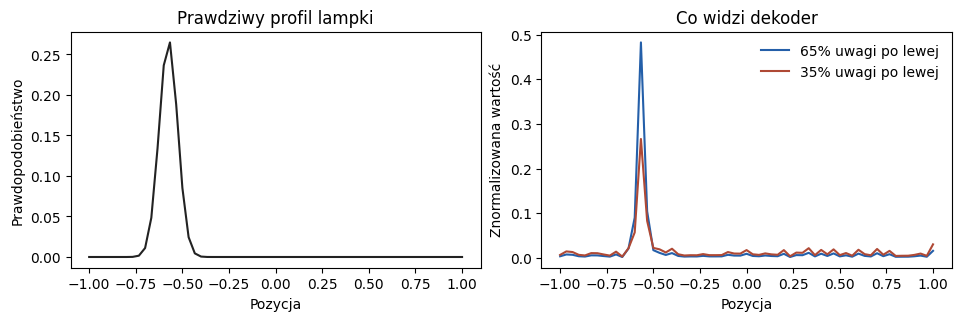

In [3]:
def make_generator(seed):
    """Tworzy generator PyTorch dla wskazanego ziarna. Inne ziarno zmienia losowania."""
    return torch.Generator().manual_seed(seed)


def make_basis(side, rng):
    """Zwraca prawdziwe profile [próba, pozycja].

    side określa stronę każdej lampki, rng steruje położeniem i szerokością.
    """
    center = CENTERS[side] + CENTER_JITTER * (torch.rand(len(side), generator=rng) - 0.5)  # Większy jitter rozsuwa pozycje prób.
    width = MIN_WIDTH + WIDTH_RANGE * torch.rand(len(side), generator=rng)  # Większa szerokość spłaszcza profil.
    log_profile = -0.5 * ((GRID - center[:, None]) / width[:, None]).square()  # Odległość od środka obniża log wagi.
    return log_profile.softmax(dim=-1)


def make_frame(basis, focus, background_error, noise, present):
    """Tworzy klatki wejściowe [próba, pozycja].

    basis to prawdziwy profil, focus to udziały uwagi [próba, strona].
    background_error podaje błąd średniej pomiarów tła przed skalowaniem.
    noise to standardowy szum bieżącej klatki. present włącza sygnał lampki.
    """
    contrast = PERIPHERAL_CONTRAST + (FOCAL_CONTRAST - PERIPHERAL_CONTRAST) * focus[:, SIDES]  # Więcej uwagi = silniejszy odczyt.
    lamp = basis / basis.amax(dim=1, keepdim=True)  # Szczyt lampki to 1 przed nadaniem jej kontrastu.
    signal = (contrast * lamp * present[:, None]  # Pusta klatka ma ten składnik równy 0.
              + FRAME_NOISE * noise             # Zakłócenie bieżącej klatki.
              - BACKGROUND_NOISE * background_error)  # Reszta po odjęciu oszacowanego tła.
    return (signal / TEMPERATURE).softmax(dim=-1)


example_rng = make_generator(23)  # Ziarno wyłącznie dla ilustracji. Inne da inną przykładową klatkę.
example_basis = make_basis(torch.tensor([0]), example_rng)  # Przykładowa lampka po lewej.
example_focus = torch.tensor([[0.65, 0.35], [0.35, 0.65]])  # Zmiana pierwszej kolumny zmienia uwagę po lewej.
example_noise = torch.randn((1, len(GRID)), generator=example_rng)  # Ten sam szum klatki dla obu odczytów.
example_background = torch.zeros_like(example_noise)  # W ilustracji tło oszacowano bez błędu.
example_present = torch.ones(2, dtype=torch.bool)  # Lampka włączona w obu wariantach.
example_frames = make_frame(example_basis, example_focus, example_background, example_noise, example_present)  # Dwa odczyty tej samej lampki.

figure, axes = plt.subplots(1, 2, figsize=(9.5, 3.1), layout='constrained')  # Dwa panele obok siebie.
axes[0].plot(GRID, example_basis[0], color='#222222')
axes[0].set(title='Prawdziwy profil lampki', xlabel='Pozycja', ylabel='Prawdopodobieństwo')
axes[1].plot(GRID, example_frames[0], color=COLORS['valid'], label='65% uwagi po lewej')
axes[1].plot(GRID, example_frames[1], color=COLORS['invalid'], label='35% uwagi po lewej')
axes[1].set(title='Co widzi dekoder', xlabel='Pozycja', ylabel='Znormalizowana wartość')
axes[1].legend(frameon=False)
plt.show()

## Krok 4. Czego uczy się dekoder?

Dekoder ma architekturę **61 → 96 → 64 → 61**. Podczas treningu losujemy stronę lampki, podział uwagi i liczbę pomiarów tła. Udziały uwagi pochodzą tu z losowania jednostajnego, dzięki czemu sieć widzi różne poziomy kontrastu. W 75% przykładów pojawia się lampka, więc celem jest jej profil. W pozostałych przykładach celem jest rozkład jednostajny. W teście Posnera lampka jest obecna w każdej próbie.

Entropia krzyżowa premiuje przypisywanie masy tam, gdzie znajduje się profil docelowy. Z 20 epok zachowujemy wagi o najniższej stracie na 6000 przykładów walidacyjnych, niezależnych od 60 000 przykładów uczących. W trakcie właściwej symulacji sieć przetwarza kolejne klatki przy stałych wagach.

In [4]:
def decoder_examples(size, seed):
    """Generuje size par klatka–cel. seed ustala stronę, uwagę, tło i szum."""
    rng = make_generator(seed)  # Oddzielne losowania dla treningu i walidacji.
    side = torch.randint(2, (size,), generator=rng)  # Pozycja lampki, gdy jest obecna.
    left_share = torch.rand(size, generator=rng)  # Większy udział daje mocniejszy odczyt po lewej.
    focus = torch.stack((left_share, 1 - left_share), dim=-1)  # Dwa udziały o sumie 1.
    present = torch.rand(size, generator=rng) < PRESENT_RATE  # Większy próg daje więcej przykładów z lampką.
    rounds = torch.randint(1, HORIZON + 1, (size, 1), generator=rng).float()  # Więcej rund daje dokładniejsze tło.
    basis = make_basis(side, rng)  # Docelowe profile lampki przed uwzględnieniem pustych klatek.
    background_error = (torch.randn(size, len(GRID), generator=rng)
                        / (rounds + BACKGROUND_BASELINE_READS).sqrt())  # Rozkład błędu średniej z tylu próbek.
    frame_noise = torch.randn(size, len(GRID), generator=rng)  # Niezależny standardowy szum klatki.
    inputs = make_frame(basis, focus, background_error, frame_noise, present)  # Klatki dla sieci.
    targets = torch.where(present[:, None], basis, UNIFORM)  # Pusta klatka ma płaski rozkład docelowy.
    return inputs, targets


def cross_entropy(model, inputs, targets):
    """Mierzy treningową entropię krzyżową rozkładów model(inputs) względem targets."""
    log_probabilities = model(inputs).log_softmax(dim=-1)  # Log prawdopodobieństw na siatce.
    return -(targets * log_probabilities).sum(dim=-1).mean()


def train_decoder(seed):
    """Trenuje sieć dla ziarna seed. Zwraca najlepsze wagi i straty z każdej epoki."""
    torch.manual_seed(seed)
    shuffle_rng = make_generator(seed + 300)  # Zmienia kolejność próbek między epokami.
    train_inputs, train_targets = decoder_examples(TRAIN_SIZE, seed + 500)  # Dane, z których liczymy gradienty.
    val_inputs, val_targets = decoder_examples(VALIDATION_SIZE, seed + 600)  # Osobne dane do wyboru epoki.
    first_width, second_width = HIDDEN_WIDTHS  # Większa szerokość daje warstwie więcej cech.
    model = nn.Sequential(nn.Linear(len(GRID), first_width), nn.GELU(),
                          nn.Linear(first_width, second_width), nn.GELU(),
                          nn.Linear(second_width, len(GRID)))  # Wyjście zawiera po jednej liczbie na pozycję.
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)  # Aktualizuje wagi według gradientu.
    losses = {'train': [], 'val': []}  # Niższa strata oznacza lepsze przewidywanie rozkładu według celu treningowego.
    best_loss = float('inf')  # Próg pierwszego zapisu. Później aktualizujemy po każdej poprawie.
    best_weights = None  # Kopia najlepszego stanu, niezależna od dalszych aktualizacji.

    for _ in range(EPOCHS):  # Jedna epoka obejmuje wszystkie próbki treningowe.
        model.train()
        order = torch.randperm(len(train_inputs), generator=shuffle_rng)  # Losowa kolejność dla tej epoki.
        for batch in order.split(BATCH_SIZE):  # Indeksy próbek w pojedynczej aktualizacji.
            loss = cross_entropy(model, train_inputs[batch], train_targets[batch])  # Większa wartość oznacza gorsze dopasowanie.
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            losses['train'].append(cross_entropy(model, train_inputs, train_targets).item())
            validation_loss = cross_entropy(model, val_inputs, val_targets).item()  # Ta strata wybiera wagi.
            losses['val'].append(validation_loss)
            if validation_loss < best_loss:
                best_loss = validation_loss  # Aktualny rekord walidacyjny.
                best_weights = {name: tensor.clone() for name, tensor in model.state_dict().items()}  # Kopia wszystkich parametrów.

    model.load_state_dict(best_weights)
    return model, losses

## Krok 5. Jak liczymy błąd po treningu?

`distribution_errors` dostaje przewidywany i prawdziwy rozkład na tej samej siatce. Dla głównej miary wystarcza środek prawdziwego profilu. Jeśli sieć idealnie odtworzy szeroki profil, błąd tej miary będzie równy jego wariancji. Druga miara, W₁, wykorzystuje obydwa pełne rozkłady. W jednym wymiarze można ją policzyć przez zsumowanie różnic ich dystrybuant na całej siatce.

Te miary służą do oceny efektu. Entropia krzyżowa z poprzedniego kroku służy do uczenia wag. Poniżej sprawdzamy przykład z rozkładem skupionym po obu stronach prawdziwego środka oraz przypadek identycznych rozkładów dla W₁.

In [5]:
def distribution_errors(prediction, basis):
    """Zwraca po jednej wartości błędu lokalizacji i W₁ na próbę.

    prediction jest rozkładem z dekodera, basis prawdziwym profilem lampki.
    Oba mają kształt [próba, pozycja] i sumę 1 w wierszu.
    """
    true_center = (basis * GRID).sum(dim=-1, keepdim=True)  # Środek prawdziwego profilu w każdej próbie.
    distance_squared = (GRID - true_center).square()  # Koszt rośnie z kwadratem odległości od tego środka.
    localization_error = (prediction * distance_squared).sum(dim=-1)  # Średni koszt pod rozkładem sieci.
    cdf_gap = (prediction - basis).cumsum(dim=-1)[..., :-1].abs()  # Różnica masy na lewo od kolejnych pozycji.
    grid_step = GRID[1] - GRID[0]  # Odstęp pozycji. Przelicza sumę na odległość na osi.
    wasserstein = cdf_gap.sum(dim=-1) * grid_step  # Większa wartość oznacza większy transport masy.
    return localization_error, wasserstein


toy_truth = torch.zeros((1, len(GRID)))  # Punktowy profil z prawdziwym środkiem w 0.
toy_truth[:, len(GRID) // 2] = 1  # Całe prawdopodobieństwo przypada na środkową pozycję.
toy_prediction = torch.zeros_like(toy_truth)  # Rozłożymy masę symetrycznie wokół środka.
toy_points = (GRID[:, None] - torch.tensor([-0.2, 0.2])).abs().argmin(dim=0)  # Indeksy najbliższe −0,2 i +0,2.
toy_prediction[:, toy_points] = 0.5  # Każda z dwóch pozycji dostaje połowę masy.
toy_error, _ = distribution_errors(toy_prediction, toy_truth)  # Interesuje nas tu kwadrat odległości.
_, identical_w1 = distribution_errors(toy_truth, toy_truth)  # Identyczne rozkłady nie wymagają transportu masy.
torch.testing.assert_close(toy_error, GRID[toy_points].square().mean().reshape(1))
torch.testing.assert_close(identical_w1, torch.zeros_like(identical_w1))
print(f'Przykład symetrycznego przewidywania: E = {toy_error.item():.2f}')

Przykład symetrycznego przewidywania: E = 0.04


## Krok 6. Jak wygląda jedna próba i porównanie warunków?

`test_posner` najpierw symuluje mrówki dla wszystkich prób. Połowa prób zaczyna z cue po lewej, połowa po prawej. Przyszły cel przypisujemy dopiero przy tworzeniu klatek. W każdej rundzie porównujemy dwa scenariusze dla tej samej kolonii. Lampka zapala się po stronie cue albo po drugiej stronie, z tą samą szerokością, tym samym losowym przesunięciem środka i tymi samymi zakłóceniami. Dzięki sparowaniu różnica dotyczy położenia lampki względem cue.

Dla każdej próby generujemy serię niezależnych pomiarów tła. Średnia w późniejszej rundzie obejmuje również pomiary użyte wcześniej. Klatka z lampką korzysta z podziału uwagi właśnie w wybranej rundzie. Zapisujemy dwa błędy na próbę oraz historię kolonii do późniejszej interpretacji.

In [6]:
@torch.inference_mode()
def test_posner(decoder, seed, *, equal_reads=False, **colony_settings):
    """Testuje zamrożony dekoder. seed ustala kolonię i zakłócenia.

    equal_reads zachowuje jakość tła z T1. colony_settings przekazuje
    ustawienia kontroli do ant_colonies. Zwraca błędy, historię i strony cue.
    """
    rng = make_generator(seed)  # Ziarno steruje tłem i szumem pojedynczej klatki.
    cue_side = torch.arange(TRIALS) % 2  # Naprzemiennie lewa i prawa strona, aby je zrównoważyć.
    frame_shape = (TRIALS, len(GRID))  # Liczba prób × liczba pozycji.
    history = ant_colonies(cue_side.numpy(), seed + 1000, **colony_settings)  # Tu rozdziela się uwaga.
    background_sums = torch.randn(HORIZON + BACKGROUND_BASELINE_READS, *frame_shape,
                                  generator=rng).cumsum(dim=0)  # Wcześniejsze pomiary wchodzą do kolejnych średnich.
    frame_noise = torch.randn(frame_shape, generator=rng)  # Ten sam szum w parze scenariuszy.
    present = torch.ones(TRIALS, dtype=torch.bool)  # W teście cel zawsze się pojawia.
    results = {'valid': {'error': [], 'w1': []},
               'invalid': {'error': [], 'w1': []}}  # Zachowujemy wyniki per próba i runda dla obu warunków.

    for condition, target_side in (('valid', cue_side), ('invalid', 1 - cue_side)):  # Warunki różnią się relacją celu do cue.
        basis = make_basis(target_side, make_generator(seed + 2000))  # Wspólne losowania szerokości i przesunięcia.
        for t in range(1, HORIZON + 1):  # t określa, w której rundzie pojawia się lampka.
            reads = BACKGROUND_BASELINE_READS + (1 if equal_reads else t)  # Więcej pomiarów daje dokładniejszą średnią.
            background_error = background_sums[reads - 1] / reads  # Średnia z dotychczasowych pomiarów tła.
            frame = make_frame(basis, history['focus'][t - 1], background_error,
                               frame_noise, present)  # Jedna klatka z lampką i bieżącym podziałem uwagi.
            prediction = decoder(frame).softmax(dim=-1)  # Masa prawdopodobieństwa dla każdej pozycji.
            error, w1 = distribution_errors(prediction, basis)  # Dwie miary dla każdego odczytu.
            results[condition]['error'].append(error)
            results[condition]['w1'].append(w1)

    # Wymiary macierzy wyników to [runda, próba].
    return {condition: {metric: torch.stack(per_round) for metric, per_round in group.items()}
            for condition, group in results.items()}, history, cue_side

## Krok 7. Trzy losowania i sposób czytania wykresów

Każdy przebieg ma osobny trening i osobny zestaw 1800 sparowanych prób na rundę. Pierwszy przebieg odpowiada głównemu wykresowi. Pozostałe pokazują, jak wynik zmienia się po zmianie losowań. Dodatkowo wykorzystujemy pierwszy dekoder do kontroli bez cue i do kontroli bez zużycia zasobu.

Na lewym wykresie **niżej znaczy lepiej**. Najpierw niebieska krzywa jest niżej od czerwonej. W pewnym momencie trend się odwraca. Na prawym wykresie sprawdzamy bezpośrednio podział mrówek. Poziom 50% oznacza równe skupienie, a przebieg powyżej niego oznacza przewagę strony cue. Dalsze rundy pomagają zobaczyć, jak obie strony zbliżają się ponownie do podziału pół na pół.

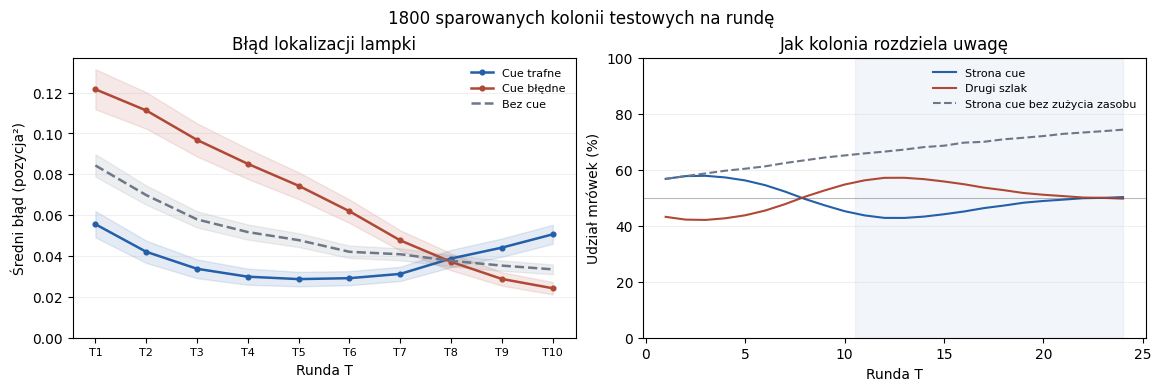

In [7]:
def mean_by_cue(values, cue_side):
    """Uśrednia values [runda, próba, strona] po stronie cue i po przeciwnej."""
    colonies = torch.arange(len(cue_side))  # Indeks każdej kolonii do wyboru właściwej strony.
    cued = values[:, colonies, cue_side].mean(dim=1)  # Średnia po stronach wskazanych przez cue.
    opposite = values[:, colonies, 1 - cue_side].mean(dim=1)  # Średnia po pozostałych stronach.
    return cued, opposite


def errors_for(results, condition, metric='error'):
    """Wybiera metric dla condition i STAGES. W neutralnym uśrednia oba położenia."""
    round_indices = [t - 1 for t in STAGES]  # Rundy w tekście liczymy od 1, indeksy od 0.
    if condition == 'neutral':
        pooled = (results['valid'][metric] + results['invalid'][metric]) / 2  # Średnia dwóch położeń w próbie bez cue.
        return pooled[round_indices]
    return results[condition][metric][round_indices]


def plot_errors(ax, results, title, *, metric='error', neutral_results=None, legend=False):
    """Rysuje wybraną metric na osi ax z przybliżonymi punktowymi pasmami 95% CI.

    results zawiera warunki cue, a neutral_results opcjonalnie dodaje bez cue.
    title nazywa panel, legend włącza etykiety krzywych.
    """
    groups = [('valid', results), ('invalid', results)]  # Główne dwa warunki.
    if neutral_results is not None:
        groups.append(('neutral', neutral_results))
    for condition, group in groups:  # Stan określa kolor, etykietę i wybór prób.
        errors = errors_for(group, condition, metric)  # Osobny błąd każdej próby w każdej rundzie.
        average = errors.mean(dim=1)  # Punkt wykresu jest średnią prób.
        standard_error = errors.std(dim=1) / errors.shape[1] ** 0.5  # Więcej prób zwęża pasmo średniej.
        margin = CI_MULTIPLIER * standard_error  # Odległość od średniej do granicy pasma.
        color = COLORS[condition]  # Rozróżnienie wizualne warunku.
        line_style = '--' if condition == 'neutral' else '-o'  # Przerywana linia to kontrola bez cue.
        ax.plot(STAGES, average, line_style, color=color, label=LABELS[condition], lw=1.8, ms=3.4)
        ax.fill_between(STAGES, average - margin, average + margin, color=color, alpha=0.12)

    ax.set(title=title, xlabel='Runda T', ylim=(0, None))
    ax.set_xticks(STAGES, [f'T{t}' for t in STAGES], fontsize=8)
    ax.grid(axis='y', alpha=0.18)
    if legend:
        ax.legend(frameon=False, fontsize=8)


runs = []  # Przechowuje wyniki, stan kolonii i przypisania cue z kolejnych przebiegów.
for run_index, (training_seed, test_seed) in enumerate(RUN_SEEDS, start=1):  # Każda para ziaren daje odrębny przebieg.
    decoder, training_losses = train_decoder(training_seed)  # Nowe wagi i krzywe treningowe tego przebiegu.
    runs.append(test_posner(decoder, test_seed))
    if run_index == 1:
        main_decoder, main_losses = decoder, training_losses  # Pierwszy model służy wykresom i kontrolom.

main_results, main_history, cue_side = runs[0]  # Pierwszy przebieg odczytu i historii mrówek.
main_test_seed = RUN_SEEDS[0][1]  # W kontrolach ponawiamy ten sam scenariusz losowy.
neutral_results, _, _ = test_posner(main_decoder, main_test_seed, initial_cue=0)  # Wyłącza przewagę początkową.
no_depletion_results, no_depletion_history, _ = test_posner(
    main_decoder, main_test_seed, consumption=0)  # Zasób przestaje ubywać. Pozostałe reguły działają.

all_rounds = range(1, HORIZON + 1)  # Dłuższy wykres uwagi pozwala zobaczyć późną dynamikę.
cued_focus, opposite_focus = mean_by_cue(main_history['focus'], cue_side)  # Średni podział uwagi.
no_depletion_focus, _ = mean_by_cue(no_depletion_history['focus'], cue_side)  # Podział bez zużycia zasobu.

figure, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), layout='constrained')  # Obok siebie skutek i mechanizm.
plot_errors(axes[0], main_results, 'Błąd lokalizacji lampki', neutral_results=neutral_results, legend=True)
axes[0].set_ylabel('Średni błąd (pozycja²)')
axes[1].plot(all_rounds, 100 * cued_focus, color=COLORS['valid'], label='Strona cue')
axes[1].plot(all_rounds, 100 * opposite_focus, color=COLORS['invalid'], label='Drugi szlak')
axes[1].plot(all_rounds, 100 * no_depletion_focus, '--', color=COLORS['neutral'],
             label='Strona cue bez zużycia zasobu')
axes[1].axhline(50, color='#303a4b', lw=0.8, alpha=0.35)
axes[1].axvspan(STAGES[-1] + 0.5, HORIZON, color='#d2dbea', alpha=0.27)
axes[1].set(title='Jak kolonia rozdziela uwagę', xlabel='Runda T', ylabel='Udział mrówek (%)', ylim=(0, 100))
axes[1].grid(axis='y', alpha=0.18)
axes[1].legend(frameon=False, fontsize=8)
figure.suptitle(f'{TRIALS} sparowanych kolonii testowych na rundę')
plt.show()

## Krok 8. Jak sprawdzamy, co powoduje odwrócenie?

**Bez zużywania zasobu** ustawiamy jego ubytek na zero. Cue nadal wygasa. W domyślnym przebiegu sama utrata cue nie przenosi przewagi na drugi szlak. **Bez wygaszania cue** zachęta przez cały czas pozostaje na początkowym poziomie. Pokazuje to, co potrafi zmienić zużywanie zasobu, gdy błysk wciąż faworyzuje pierwotną stronę.

**Tło o jakości jak w T1** powtarza tę samą średnią z pierwszych pięciu odczytów w każdej rundzie. Dzięki temu możemy zobaczyć zmianę wywołaną przez ruch mrówek przy stałym wkładzie tła. **Wasserstein W₁** ponownie ocenia główne klatki, tym razem porównując pełne rozkłady. Wszystkie kontrole korzystają z tych samych wag dekodera.

Dolne wykresy pokazują stan zasobu i feromonu. Przy większym ruchu początkowa strona traci więcej zasobu. Wraz ze spadkiem liczby udanych wypraw spada zasilanie jej szlaku świeżym feromonem.

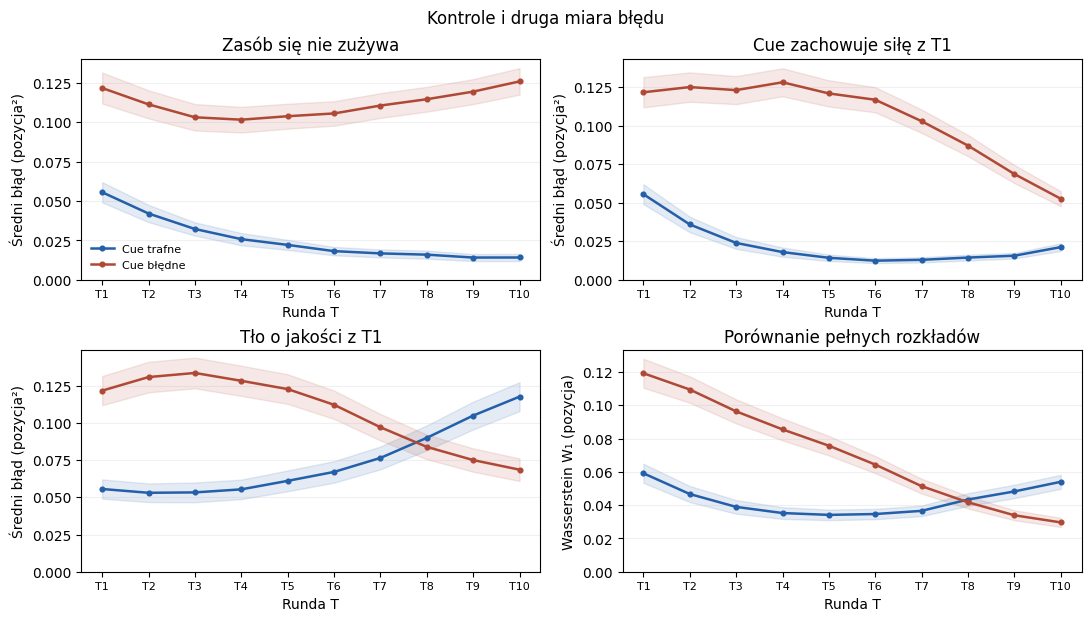

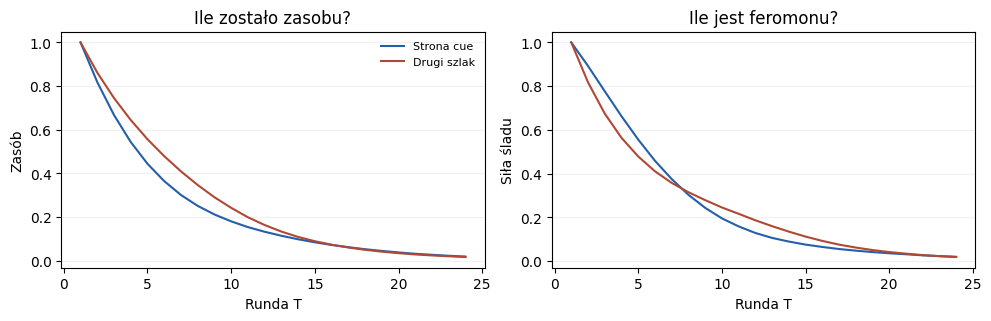

In [8]:
persistent_cue_results, _, _ = test_posner(main_decoder, main_test_seed, cue_retention=1)  # Zachowuje cue z T1.
fixed_background_results, _, _ = test_posner(main_decoder, main_test_seed, equal_reads=True)  # Zatrzymuje poprawę tła.
figure, axes = plt.subplots(2, 2, figsize=(10.8, 6.1), layout='constrained')  # Cztery porównania jednej zmiany.
plot_errors(axes[0, 0], no_depletion_results, 'Zasób się nie zużywa', legend=True)
plot_errors(axes[0, 1], persistent_cue_results, 'Cue zachowuje siłę z T1')
plot_errors(axes[1, 0], fixed_background_results, 'Tło o jakości z T1')
plot_errors(axes[1, 1], main_results, 'Porównanie pełnych rozkładów', metric='w1')
for ax in axes.flat[:-1]:  # Trzy pierwsze panele mają tę samą jednostkę.
    ax.set_ylabel('Średni błąd (pozycja²)')
axes[1, 1].set_ylabel('Wasserstein W₁ (pozycja)')
figure.suptitle('Kontrole i druga miara błędu')
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(9.8, 3.1), layout='constrained')  # Stan obu szlaków w czasie.
for ax, key, title, ylabel in (
    (axes[0], 'food', 'Ile zostało zasobu?', 'Zasób'),
    (axes[1], 'pheromone', 'Ile jest feromonu?', 'Siła śladu'),
):  # Każda krotka wybiera panel, wielkość i jej opis.
    cued_state, opposite_state = mean_by_cue(main_history[key], cue_side)  # Stan po obu stronach względem cue.
    ax.plot(all_rounds, cued_state, color=COLORS['valid'], label='Strona cue')
    ax.plot(all_rounds, opposite_state, color=COLORS['invalid'], label='Drugi szlak')
    ax.set(title=title, xlabel='Runda T', ylabel=ylabel)
    ax.grid(axis='y', alpha=0.18)
axes[0].legend(frameon=False, fontsize=8)
plt.show()

## Krok 9. Jak odczytać liczby?

Dla każdego losowania pokazujemy pierwsze cztery punkty i minimum błędu przy trafnym cue. Następnie wyszukujemy pierwszą późniejszą rundę, w której średni błąd trafnego cue jest większy od błędu błędnego cue. To definicja przecięcia użyta w zestawieniu. Dodatnia różnica na końcu znaczy, że późne trafne cue pogarsza odczyt względem błędnego w tym modelu. Przedział dla różnicy liczymy z różnic **w parach prób**, więc zachowujemy sparowanie szumu i podziału uwagi.

In [9]:
for run_index, (results, history, side) in enumerate(runs, start=1):  # Osobne losowanie treningu i kolonii.
    valid_average = errors_for(results, 'valid').mean(dim=1)  # Średnie dla lampki po stronie cue.
    invalid_average = errors_for(results, 'invalid').mean(dim=1)  # Średnie dla lampki po drugiej stronie.
    minimum_index = int(valid_average.argmin())  # Indeks rundy z najmniejszym błędem trafnego cue.
    crossings = [t for i, t in enumerate(STAGES)
                 if i > minimum_index and valid_average[i] > invalid_average[i]]  # Kandydaci na późne przecięcie.
    crossing = f'T{crossings[0]}' if crossings else 'brak w tym oknie'  # Pierwsza zaobserwowana zmiana przewagi.
    last_gap = errors_for(results, 'valid')[-1] - errors_for(results, 'invalid')[-1]  # Różnice w parach w ostatniej rundzie.
    gap_average = last_gap.mean()  # Dodatni wynik oznacza większy błąd przy trafnym cue.
    gap_margin = CI_MULTIPLIER * last_gap.std() / len(last_gap) ** 0.5  # Przybliżone 95% CI średniej różnicy.
    focus, _ = mean_by_cue(history['focus'], side)  # Średnia uwaga po stronie cue w kolejnych rundach.
    print(f'Przebieg {run_index}. Minimum trafnego cue: T{STAGES[minimum_index]}. Przecięcie: {crossing}.')
    print('  Trafne, pierwsze 4 T: ' + ' → '.join(f'{value:.3f}' for value in valid_average[:4]))
    print('  Błędne, pierwsze 4 T: ' + ' → '.join(f'{value:.3f}' for value in invalid_average[:4]))
    print(f'  Mrówki po stronie cue: {focus[STAGES[0] - 1]:.1%} → {focus[STAGES[-1] - 1]:.1%} (pierwsza i ostatnia runda).')
    print(f'  Różnica błędów w T{STAGES[-1]}: {gap_average:.3f}, '
          f'95% CI [{gap_average - gap_margin:.3f}, {gap_average + gap_margin:.3f}].')
    torch.testing.assert_close(history['focus'].sum(dim=-1), torch.ones_like(history['focus'][..., 0]))
    assert torch.all(history['food'][1:] <= history['food'][:-1]), 'Zasób nie powinien rosnąć w trakcie próby.'

best_epoch = int(torch.tensor(main_losses['val']).argmin()) + 1  # Epoka o najmniejszej stracie walidacyjnej.
print(f'Pierwszy dekoder używa wag z epoki {best_epoch}.')

Przebieg 1. Minimum trafnego cue: T5. Przecięcie: T8.
  Trafne, pierwsze 4 T: 0.056 → 0.042 → 0.034 → 0.030
  Błędne, pierwsze 4 T: 0.122 → 0.111 → 0.097 → 0.085
  Mrówki po stronie cue: 56.8% → 45.2% (pierwsza i ostatnia runda).
  Różnica błędów w T10: 0.026, 95% CI [0.021, 0.032].
Przebieg 2. Minimum trafnego cue: T5. Przecięcie: T9.
  Trafne, pierwsze 4 T: 0.048 → 0.034 → 0.028 → 0.024
  Błędne, pierwsze 4 T: 0.113 → 0.101 → 0.094 → 0.079
  Mrówki po stronie cue: 57.0% → 45.3% (pierwsza i ostatnia runda).
  Różnica błędów w T10: 0.023, 95% CI [0.017, 0.029].
Przebieg 3. Minimum trafnego cue: T6. Przecięcie: T9.
  Trafne, pierwsze 4 T: 0.049 → 0.034 → 0.027 → 0.025
  Błędne, pierwsze 4 T: 0.125 → 0.112 → 0.102 → 0.086
  Mrówki po stronie cue: 57.0% → 45.3% (pierwsza i ostatnia runda).
  Różnica błędów w T10: 0.024, 95% CI [0.018, 0.030].
Pierwszy dekoder używa wag z epoki 19.


## Co wynika z modelu?

Przy domyślnych ustawieniach pierwszy wykres daje łagodny spadek wczesnego błędu. Dla trafnego cue pierwsze cztery punkty to około **0,056 → 0,042 → 0,034 → 0,030**, a dla błędnego **0,122 → 0,111 → 0,097 → 0,085**. W trzech przebiegach późne przecięcie pojawia się w T8 albo T9. To rezultat działania reguł przy konkretnych parametrach i losowaniach.

Skupienie zmienia siłę odczytu lampki. Poprawa oszacowania tła jest osobnym mechanizmem i pomaga obu stronom. Zużycie zasobu, słabsze wzmacnianie feromonu i losowa eksploracja tworzą zmianę preferowanego szlaku. Ten podział ról widać po wyłączeniu mechanizmów pojedynczo.

Zachowanie człowieka mierzy się m.in. czasem reakcji. W notebooku mierzymy błąd lokalizacji i udział mrówek, a T jest jednostką symulacji. Zgodność kierunku efektu daje hipotezę do sprawdzenia. Aby powiązać wartości błędu lub rundy z zachowaniem ludzi, potrzebna byłaby osobna kalibracja na danych. [Satel, Wilson i Klein, 2019 — przegląd mechanizmów IOR](https://pubmed.ncbi.nlm.nih.gov/31735859/)